# Demo SVA-Agent

In [1]:
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent / "src"))

from sva.agent import SVAAgent
from sva.config import RESULTS_DIR
from sva.eval import load_split
from sva.perception import PerceptionCache

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b4ae"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 90})
agent = SVAAgent("qwen_local_3b", theta=0.2)          # nap Qwen 3B mot lan (~1 phut)
cache = PerceptionCache()

def show_frames(paths, n=6, title=""):
    fig, axes = plt.subplots(len(paths), n, figsize=(2 * n, 1.4 * len(paths)), squeeze=False)
    for r, p in enumerate(paths):
        frames, ts = cache.get_frames(p, n, 336)
        for c in range(n):
            axes[r, c].imshow(frames[c]); axes[r, c].axis("off"); axes[r, c].set_title(f"{ts[c]:.1f}s", fontsize=7)
    fig.suptitle(title, fontsize=9); plt.tight_layout(); plt.show()

def show_evidence(out, keys, texts, gold=None):
    evs = out["evidence"]
    fig, axes = plt.subplots(1, len(evs) + 1, figsize=(3.2 * (len(evs) + 1), 2.6), sharey=True)
    for ax, e in zip(axes, evs + [{"tool_name": "KẾT QUẢ GỘP", "dist": out["dist"]}]):
        vals = [e["dist"][k] for k in keys]
        ax.bar(range(len(keys)), vals, color=[ORANGE if k == gold else BLUE for k in keys])
        ax.set_xticks(range(len(keys)), keys, fontsize=7); ax.set_title(e["tool_name"], fontsize=9); ax.set_ylim(0, 1)
    plt.tight_layout(); plt.show()

## 1. Một câu SoccerBench bất kỳ (giấu tên task)

How does the camera position change in the video?
  O1. From Main camera right to Main camera left.
  O2. From Main camera left to Main camera left.
  O3. From Spider camera to Public.
  O4. From Close-up side staff to Main camera left.   <- dap an


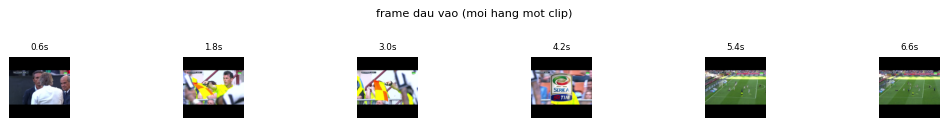

In [2]:
TASK, INDEX = "q8", 0                       # doi o day: q8, q9, q10, q11, q13, q14 va so thu tu trong tap test
s = load_split(TASK, "test")[INDEX]
print(s.question)
for k in s.option_keys:
    print(f"  {k}. {s.option_texts[k]}" + ("   <- dap an" if k == s.gold_key else ""))
show_frames(s.materials[:5], title="frame dau vao (moi hang mot clip)")

Question Agent doan: q8 (theo rule) | nhanh: B
SVA chon: O4 | dap an: O4 | do tin: 0.162 | dung vi: het luot
  Reasoner: more_frames - phan van dan trai -> lay them thong tin
  Reasoner: reorder - thu hanh dong con lai
  Reasoner: pairwise - thu hanh dong con lai


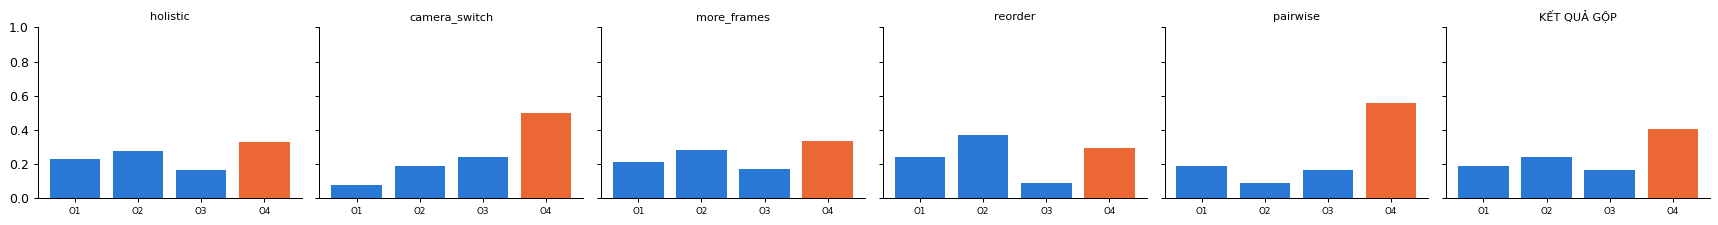

holistic           
camera_switch      dau: Close-up player or field referee 0.47 | cuoi: Main behind the goal 0.43
more_frames        
reorder            
pairwise           O4 vs O2: 0.86 / 0.14


In [3]:
out = agent(s)                              # an task_id that: Question Agent tu doan
print("Question Agent doan:", out["task_pred"], "(theo", out["route"] + ")", "| nhanh:", out["branch"])
print("SVA chon:", out["pred"], "| dap an:", s.gold_key, "| do tin:", round(out["confidence"], 3), "| dung vi:", out["stop"])
for st in out["steps"]:
    if "action" in st:
        print("  Reasoner:", st["action"], "-", st["reason"])
show_evidence(out, s.option_keys, s.option_texts, s.gold_key)
for e in out["evidence"]:
    print(f"{e['tool_name']:<18} {e['raw_observation'][:110]}")

## 2. Cùng câu đó ở chế độ Open (giấu phương án)

In [4]:
open_out = agent.grounding.solve_open(replace(s, task_id=out["task_pred"]))
print("Ung vien tu tao:", list(open_out["candidates"].values())[:8], "..." if len(open_out["candidates"]) > 8 else "")
print("Tra loi (nhan):", open_out["open_pred"])
print("Anh xa vao phuong an:", open_out["pred"], f"({open_out['select']})", "| dap an:", s.gold_key, "| dap an mo:", s.open_answer)

Ung vien tu tao: ['From Close-up player or field referee to Main behind the goal.', 'From Close-up side staff to Main behind the goal.', 'From Main camera center to Main behind the goal.', 'From Close-up player or field referee to Main camera center.'] 
Tra loi (nhan): From Close-up player or field referee to Main behind the goal.
Anh xa vao phuong an: O4 (llm) | dap an: O4 | dap an mo: From Close-up side staff to Main camera left.


## 3. Hỏi về một video dài

In [5]:
items = json.loads((RESULTS_DIR / "agent" / "long_items.json").read_text(encoding="utf-8"))
video = [i for i in items if i["task"] == "q10"][0]["video"]
print(video)
for q, opts in [("What happens at 1:45?", None),
                ("What kind of football event is depicted at 0:40? ", {"O1": "corner", "O2": "goal", "O3": "throw in", "O4": "clearance"})]:
    r = agent.ask([video], q, opts, out_dir=RESULTS_DIR / "agent" / "ask" / "demo")
    print("\nQ:", q)
    print("A:", r["answer"])
    print("   task", r["task"], "| doan", r["segments"][0], "| trang thai", r["status"])

D:\UITs subject\soccer-video-agent\data\cache\agent\long\q10_0.mp4



Q: What happens at 1:45?
A: At 1:30-2:00: corner (confidence 0.76).
   task q10 | doan D:\UITs subject\soccer-video-agent\data\cache\agent\long\q10_0.mp4#t=90.00,120.00 | trang thai answered



Q: What kind of football event is depicted at 0:40? 
A: At 0:25-0:55: clearance (confidence 0.67).
   task q10 | doan D:\UITs subject\soccer-video-agent\data\cache\agent\long\q10_0.mp4#t=25.00,55.00 | trang thai answered


Q: Which earlier play is shown again in the replay at 1:28?
A: Not sure. Most likely: 0:00-0:15 (46%), then 0:15-0:34 (21%). Please check 1:22-1:34.
doan dung (that): [20.0, 40.0]


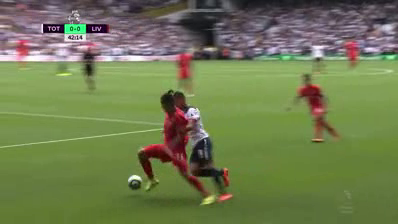

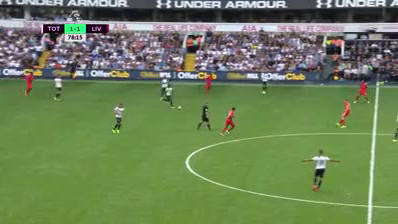

In [6]:
it = [i for i in items if i["task"] == "q9"][0]
r = agent.ask([it["video"]], it["question"], out_dir=RESULTS_DIR / "agent" / "ask" / "demo_q9")
print("Q:", it["question"]); print("A:", r["answer"]); print("doan dung (that):", it["span"])
for f in r["frames"]:
    display(Image(f, width=320))

## 4. Câu ngoài phạm vi và câu thiếu thông tin

In [7]:
for q in ["Who scored the most goals in this season?", "What happens in this video?"]:
    r = agent.ask([video], q)
    print("Q:", q); print("A:", r["answer"], f"[{r['status']}]\n")

Q: Who scored the most goals in this season?
A: This question is outside what can be answered from the video (camera changes, replays, events, commentary, jersey colors, fouls). [out_of_scope]

Q: What happens in this video?
A: The video is 2.5 minutes long. Please say when (e.g. 'at 1:10'). [clarify]

